In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv("../train.csv")

In [14]:
df.head()

,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Delayed
0,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1


In [15]:
df.tail()

,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Delayed
4495,2024-02-09,Dubai,Hamburg,Air,Electronics,9346.56,232.67,2.49,2.4,Hurricane,0.884,4.43,1
4496,2025-02-09,Rotterdam,Dubai,Rail,Pharmaceuticals,7578.58,248.16,3.73,8.9,Fog,0.611,11.29,1
4497,2024-12-05,Rotterdam,Singapore,Road,Pharmaceuticals,2431.14,214.42,2.67,9.1,Clear,0.985,1.87,0
4498,2025-12-08,Los Angeles,Singapore,Air,Automotive,4289.33,478.05,2.34,4.2,Clear,0.818,0.77,0
4499,2024-08-31,Busan,Rotterdam,Sea,Electronics,6576.94,108.15,2.69,6.6,Hurricane,0.846,97.87,1


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       4500 non-null   str    
 1   Origin_Port                4500 non-null   str    
 2   Destination_Port           4500 non-null   str    
 3   Transport_Mode             4500 non-null   str    
 4   Product_Category           4500 non-null   str    
 5   Distance_km                4500 non-null   float64
 6   Weight_MT                  4500 non-null   float64
 7   Fuel_Price_Index           4500 non-null   float64
 8   Geopolitical_Risk_Score    4500 non-null   float64
 9   Weather_Condition          4500 non-null   str    
 10  Carrier_Reliability_Score  4500 non-null   float64
 11  Lead_Time_Days             4500 non-null   float64
 12  Delayed                    4500 non-null   int64  
dtypes: float64(6), int64(1), str(6)
memory usage: 457.2 KB


In [17]:
df['Date'] = pd.to_datetime(df['Date'], errors="coerce")

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       4500 non-null   datetime64[us]
 1   Origin_Port                4500 non-null   str           
 2   Destination_Port           4500 non-null   str           
 3   Transport_Mode             4500 non-null   str           
 4   Product_Category           4500 non-null   str           
 5   Distance_km                4500 non-null   float64       
 6   Weight_MT                  4500 non-null   float64       
 7   Fuel_Price_Index           4500 non-null   float64       
 8   Geopolitical_Risk_Score    4500 non-null   float64       
 9   Weather_Condition          4500 non-null   str           
 10  Carrier_Reliability_Score  4500 non-null   float64       
 11  Lead_Time_Days             4500 non-null   float64       
 12  Delayed          

In [19]:
df.head(10)

,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Delayed
0,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1
5,2024-08-16,Rotterdam,Marseille,Rail,Automotive,2761.92,44.98,4.06,2.2,Rain,0.869,2.16,1
6,2024-05-22,Shanghai,Antwerp,Rail,Pharmaceuticals,1342.21,388.62,1.31,2.6,Storm,0.981,2.99,0
7,2024-04-14,Busan,Antwerp,Air,Textiles,13059.55,423.93,3.32,5.7,Fog,0.558,1.25,1
8,2025-11-23,Dubai,Marseille,Air,Textiles,9216.17,91.73,3.72,5.0,Clear,0.855,0.62,1
9,2025-07-12,Los Angeles,Singapore,Rail,Electronics,10767.05,215.74,3.71,2.0,Storm,0.615,25.17,1


In [20]:
df.describe()

,Date,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score,Lead_Time_Days,Delayed
count,4500,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000
mean,2025-01-04 17:58:43.200000,7697.571342,246.485504,2.850553,5.079111,0.755045,19.490109,0.610222
min,2024-01-01 00:00:00,500.170000,1.030000,1.200000,0.000000,0.500000,0.500000,0.000000
25%,2024-07-03 00:00:00,4028.437500,124.637500,2.007500,2.600000,0.630000,2.160000,0.000000
50%,2025-01-07 00:00:00,7755.515000,243.620000,2.830000,5.100000,0.758000,8.350000,1.000000
75%,2025-07-09 00:00:00,11283.387500,366.940000,3.710000,7.500000,0.880000,21.382500,1.000000
max,2025-12-31 00:00:00,14995.910000,499.730000,4.500000,10.000000,1.000000,236.390000,1.000000
std,NaN,4198.103120,142.562241,0.964317,2.881834,0.144287,31.388559,0.487754


In [21]:
df.shape

(4500, 13)

In [22]:
df.isnull().sum()

Date                         0
Origin_Port                  0
Destination_Port             0
Transport_Mode               0
Product_Category             0
Distance_km                  0
Weight_MT                    0
Fuel_Price_Index             0
Geopolitical_Risk_Score      0
Weather_Condition            0
Carrier_Reliability_Score    0
Lead_Time_Days               0
Delayed                      0
dtype: int64

In [23]:
df.duplicated().sum()

np.int64(0)

In [29]:
cat_columns = df.select_dtypes(include="str").columns
cat_columns

Index(['Origin_Port', 'Destination_Port', 'Transport_Mode', 'Product_Category',
       'Weather_Condition'],
      dtype='str')

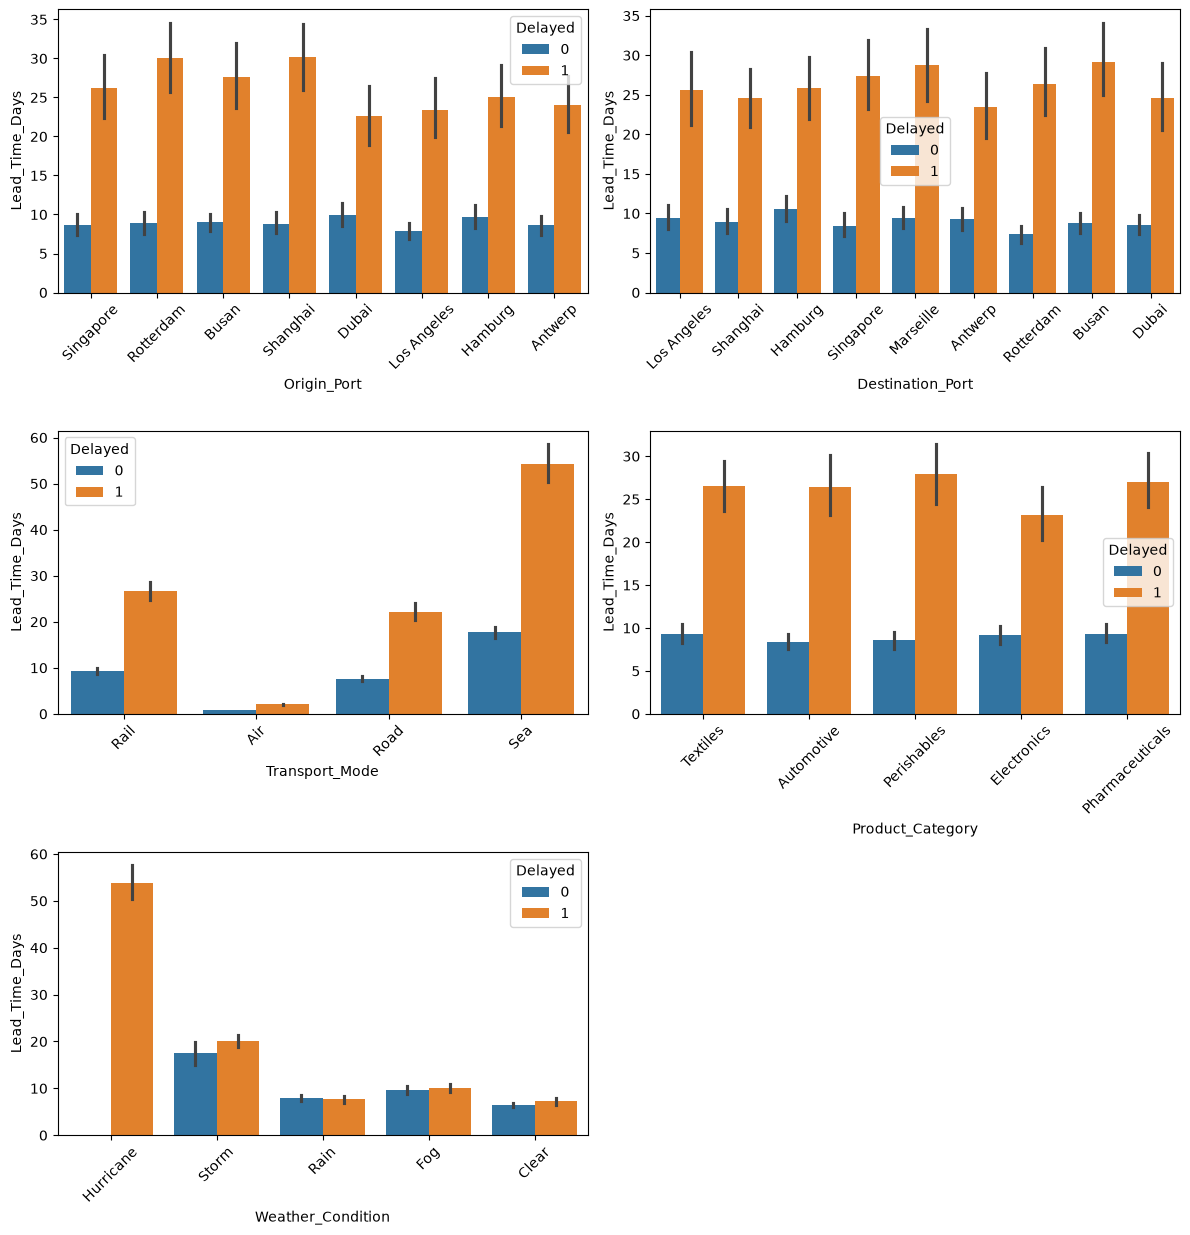

In [54]:
plt.figure(figsize=(12,12))
for i, cat in enumerate(cat_columns, start=1):
    plt.subplot(3,2,i)
    sns.barplot(x=df[cat], y=df['Lead_Time_Days'], hue=df['Delayed'])
    plt.tight_layout()
    plt.xticks(rotation=45)

<Axes: xlabel='Delayed', ylabel='count'>

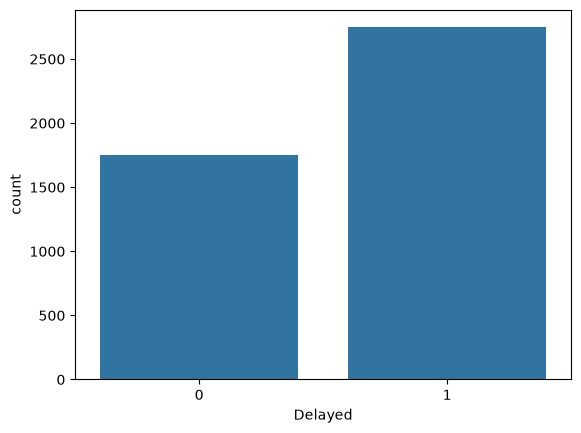

In [68]:
sns.barplot(x=df['Delayed'].value_counts().index, y=df['Delayed'].value_counts())

<Axes: >

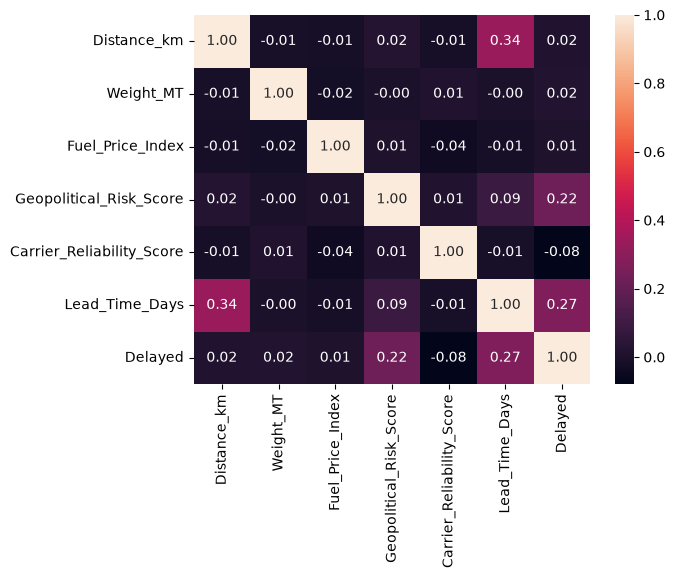

In [69]:
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f")

In [70]:
df.head()

,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Delayed
0,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1


In [73]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

In [75]:
df = df.drop(columns=['Date'])

In [76]:
df.head()

,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Delayed,Year,Month,Day
0,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1,2025,10,16
1,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1,2024,4,24
2,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0,2024,1,26
3,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1,2024,10,8
4,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1,2024,9,7


In [77]:
df = df[['Year','Month','Day','Origin_Port','Destination_Port','Transport_Mode','Product_Category','Distance_km','Weight_MT'
         ,'Fuel_Price_Index','Geopolitical_Risk_Score','Weather_Condition','Carrier_Reliability_Score','Lead_Time_Days','Delayed']]

In [78]:
df

,Year,Month,Day,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Delayed
0,2025,10,16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,2024,4,24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,2024,1,26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,2024,10,8,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,2024,9,7,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4495,2024,2,9,Dubai,Hamburg,Air,Electronics,9346.56,232.67,2.49,2.4,Hurricane,0.884,4.43,1
4496,2025,2,9,Rotterdam,Dubai,Rail,Pharmaceuticals,7578.58,248.16,3.73,8.9,Fog,0.611,11.29,1
4497,2024,12,5,Rotterdam,Singapore,Road,Pharmaceuticals,2431.14,214.42,2.67,9.1,Clear,0.985,1.87,0
4498,2025,12,8,Los Angeles,Singapore,Air,Automotive,4289.33,478.05,2.34,4.2,Clear,0.818,0.77,0


In [80]:
X = df.drop(columns=['Delayed'])
y = df['Delayed']

In [81]:
numeric_feature = X.select_dtypes(include="number").columns
print(numeric_feature, "\n", cat_columns)

Index(['Year', 'Month', 'Day', 'Distance_km', 'Weight_MT', 'Fuel_Price_Index',
       'Geopolitical_Risk_Score', 'Carrier_Reliability_Score',
       'Lead_Time_Days'],
      dtype='str') 
 Index(['Origin_Port', 'Destination_Port', 'Transport_Mode', 'Product_Category',
       'Weather_Condition'],
      dtype='str')


In [86]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [87]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

In [88]:
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [89]:
preprocessing = ColumnTransformer(transformers=[
    ("scaler", numeric_pipeline, numeric_feature),
    ("onehot", cat_pipeline, cat_columns)
])

In [94]:
from sklearn.model_selection import train_test_split

In [95]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [96]:
X_train.shape

(3600, 14)

In [97]:
X_train.columns

Index(['Year', 'Month', 'Day', 'Origin_Port', 'Destination_Port',
       'Transport_Mode', 'Product_Category', 'Distance_km', 'Weight_MT',
       'Fuel_Price_Index', 'Geopolitical_Risk_Score', 'Weather_Condition',
       'Carrier_Reliability_Score', 'Lead_Time_Days'],
      dtype='str')

In [147]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [137]:
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, confusion_matrix, classification_report 
from sklearn.metrics import mean_absolute_percentage_error, f1_score, recall_score, precision_score

In [148]:
multiple_models = {
    "DecisionTreeClassifier":DecisionTreeClassifier(),
    "LogisticRegression":LogisticRegression(),
    "SVC":SVC(),
    "RandomForestClassifier":RandomForestClassifier(),
    "XGBClassifier":XGBClassifier()
}

In [149]:
results = {}

for name, model in multiple_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessing),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_train_pred = pipeline.predict(X_train)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_pred)

    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)

    results[name] = {
        "Train Accuracy":train_accuracy,
        "Test Accuracy":test_accuracy,
        "f1_score":f1,
        "recall_score":recall,
        "precision_score":precision
    }

In [150]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test Accuracy", ascending=False)
results_df

,Train Accuracy,Test Accuracy,f1_score,recall_score,precision_score
LogisticRegression,0.746389,0.733333,0.774011,0.768224,0.779886
SVC,0.815000,0.730000,0.769668,0.758879,0.780769
RandomForestClassifier,1.000000,0.726667,0.767486,0.758879,0.776291
XGBClassifier,0.999722,0.721111,0.764319,0.760748,0.767925
DecisionTreeClassifier,1.000000,0.668889,0.722533,0.725234,0.719852


In [234]:
model = LogisticRegression(C= np.float64(0.0745934328572655),class_weight= None,solver='lbfgs', random_state=42)
# model = RandomForestClassifier(max_depth= 15,max_features= 'sqrt',min_samples_leaf= 4,min_samples_split= 6,n_estimators= 330,random_state=42)

In [235]:
pipeline = Pipeline(steps=[
    ("preprocessing", preprocessing),
    ("model", model)
])

In [236]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Year','Month','Day',...,'Weather_Condition','Carrier_Reliability_Score', 'Lead_Time_Days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('onehot', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [237]:
y_pred = pipeline.predict(X_test)

In [238]:
y_train_pred = pipeline.predict(X_train)

In [239]:
print("X_train : ", accuracy_score(y_train, y_train_pred))
print("X_test : ", accuracy_score(y_test, y_pred))

X_train :  0.7455555555555555
X_test :  0.7411111111111112


<Axes: >

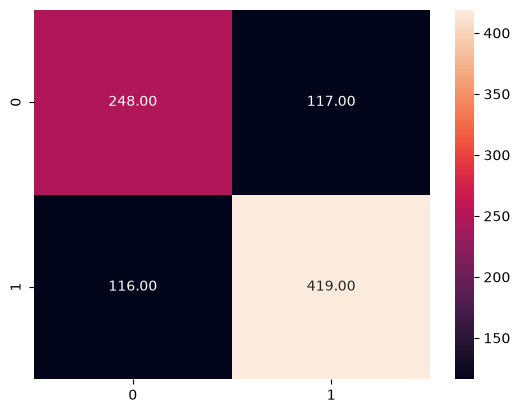

In [240]:
sns.heatmap((confusion_matrix(y_test, y_pred)), annot=True, fmt=".2f")

In [241]:
pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).T

,precision,recall,f1-score,support
0,0.681319,0.679452,0.680384,365.000000
1,0.781716,0.783178,0.782446,535.000000
accuracy,0.741111,0.741111,0.741111,0.741111
macro avg,0.731518,0.731315,0.731415,900.000000
weighted avg,0.741000,0.741111,0.741054,900.000000


In [242]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
from scipy.stats import randint

In [216]:
params_grid = {
    "model__n_estimators": randint(100, 501),
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": randint(2, 21),
    "model__min_samples_leaf": randint(1, 11),
    "model__max_features": ["sqrt", "log2", None]
}

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=params_grid,
    scoring="f1_weighted",
    n_iter=30,
    n_jobs=-1,
    verbose=2,
    cv=5,
    random_state=42
)

In [217]:
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': <scipy.stats....0025E834BDBB0>, 'model__min_samples_split': <scipy.stats....0025E831F7200>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_weighted'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum

In [218]:
random_search.best_params_

{'model__max_depth': 15,
 'model__max_features': 'sqrt',
 'model__min_samples_leaf': 4,
 'model__min_samples_split': 6,
 'model__n_estimators': 330}

In [247]:
features = pipeline.named_steps['preprocessing'].get_feature_names_out()
coeficient= pipeline.named_steps['model'].coef_[0]

In [249]:
feature_importance = {
    "Feature":features,
    "Imporatnace":coeficient,
    "Absolute_Imporatnace":abs(coeficient)
}

In [250]:
pd.DataFrame(feature_importance).sort_values(by="Absolute_Imporatnace", ascending=False)

,Feature,Imporatnace,Absolute_Imporatnace
37,onehot__Weather_Condition_Hurricane,2.091866,2.091866
35,onehot__Weather_Condition_Clear,-1.041346,1.041346
38,onehot__Weather_Condition_Rain,-0.923228,0.923228
36,onehot__Weather_Condition_Fog,-0.731729,0.731729
8,scaler__Lead_Time_Days,0.621149,0.621149
39,onehot__Weather_Condition_Storm,0.604176,0.604176
6,scaler__Geopolitical_Risk_Score,0.582237,0.582237
26,onehot__Transport_Mode_Air,0.267104,0.267104
29,onehot__Transport_Mode_Sea,-0.241228,0.241228
7,scaler__Carrier_Reliability_Score,-0.185120,0.185120


In [251]:
import pickle

pickle.dump(pipeline, open("logistic_reg_model.pkl","wb"))